# Phase 2 scratch: rebuild identities
`uid = card1 _ addr1 _ D1n` where `D1n = day - D1` (the day the account started). Validate by label purity, against a shuffled-label baseline.

In [1]:
import sys
sys.path.insert(0, '../../src')
import pandas as pd
import identity, viz
pd.set_option('display.width', 250)
identity.build_identity()
con = identity.connect()
stats = identity.compare_groupings(con)
stats.T

grouping                            card1 alone                   uid            uid + email           
labels                                     real   shuffled       real   shuffled        real   shuffled
groups                                 13553.00   13553.00  217020.00  217020.00   272922.00  272922.00
txns_covered                          590540.00  590540.00  589271.00  589271.00   589271.00  589271.00
txns_per_group_mean                       43.57      43.57       2.72       2.72        2.16       2.16
txns_per_group_median                      4.00       4.00       1.00       1.00        1.00       1.00
pct_singletons                            25.40      25.40      57.40      57.40       64.70      64.70
groups_2plus                           10109.00   10109.00   92431.00   92431.00    96263.00   96263.00
pct_pure_2plus                            84.80      65.30      96.60      85.10       97.70      86.80
fraud_groups_2plus                      1594.00    3513.00    5087.00   13825.00     4821.00   12740.00
pct_all_fraud_given_any                    3.60       0.10      39.00       0.30       54.80       0.40
pct_fraud_txns_in_pure_fraud_groups        0.90       0.00      43.80       0.50       52.40       0.50

Do mixed groups look like 'clean, then caught'? (label propagation after a chargeback)

In [2]:
con.sql('''
WITH t AS (SELECT uid g, TransactionID, isFraud FROM identity WHERE uid IS NOT NULL),
g AS (SELECT g, AVG(isFraud) s,
        MAX(TransactionID) FILTER (WHERE isFraud=0) last_clean, MIN(TransactionID) FILTER (WHERE isFraud=1) first_fraud,
        MAX(TransactionID) FILTER (WHERE isFraud=1) last_fraud, MIN(TransactionID) FILTER (WHERE isFraud=0) first_clean
      FROM t GROUP BY 1)
SELECT COUNT(*) mixed_groups,
  ROUND(100*AVG((last_clean <= first_fraud)::INT),1) pct_clean_then_fraud,
  ROUND(100*AVG((last_fraud <= first_clean)::INT),1) pct_fraud_then_clean
FROM g WHERE s > 0 AND s < 1''').df()

,mixed_groups,pct_clean_then_fraud,pct_fraud_then_clean
0,3103,21.2,22.6


Is D1n drifting by a day and splitting customers? Compare +1 day neighbors against +2, +7, +30. Similar rates mean no drift.

In [3]:
con.execute("CREATE OR REPLACE TEMP TABLE u AS SELECT DISTINCT card1, split_part(uid,'_',2) a, D1n FROM identity WHERE uid IS NOT NULL")
{k: con.execute(f'SELECT ROUND(100*AVG((u2.D1n IS NOT NULL)::INT),1) FROM u LEFT JOIN u u2 ON u2.card1=u.card1 AND u2.a=u.a AND u2.D1n=u.D1n+{k}').fetchone()[0] for k in [1, 2, 7, 30]}

{1: 20.3, 2: 20.0, 7: 19.1, 30: 16.3}

PosixPath('figures/02_identity_purity.png')

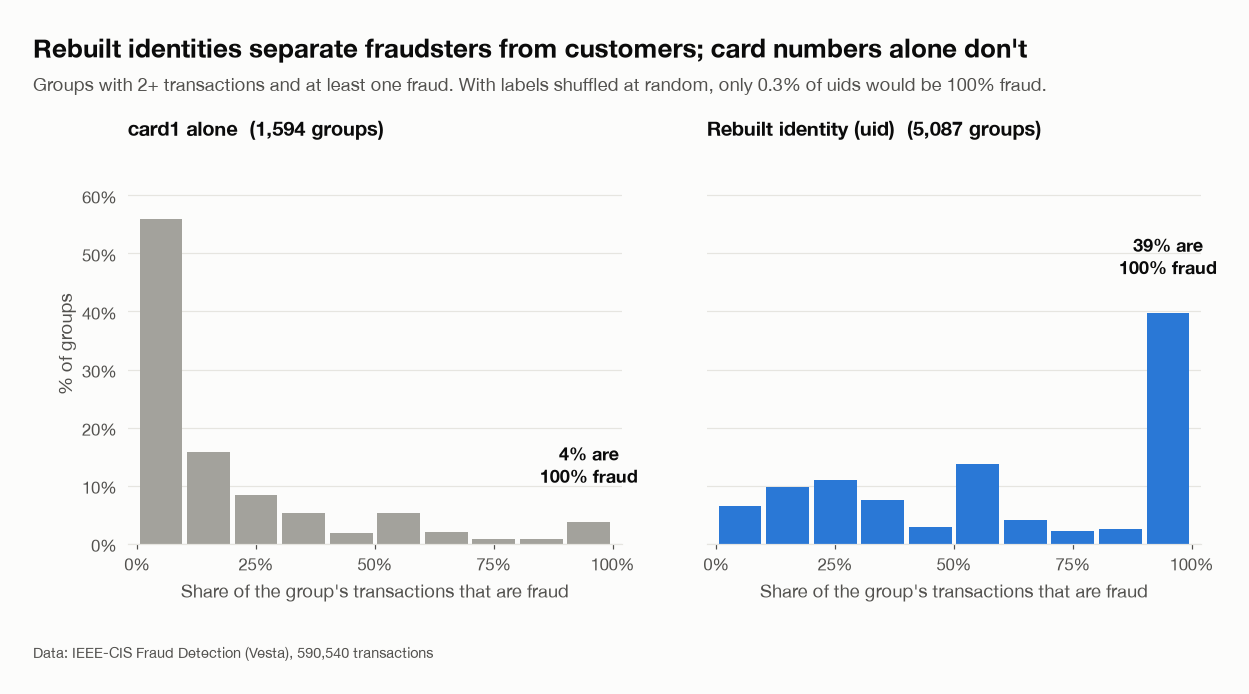

In [4]:
fig = identity.plot_purity(con, stats)
viz.save(fig, '02_identity_purity')